# LLaVA-1.5-7B: per-instance error attribution for the field experiment

The [field experiment](../run_field_scripts.sh) sweeps an added white border
("field") around each benchmark image and compares it against two controls
built from the *same* underlying image at *the same* effective resolution
(`src/utils.py:build_field_images`):

- **field** - original embedded in a larger white-bordered canvas,
- **resized** - the plain original downscaled by the coefficient the field
  image experiences during preprocessing (isolates content downscaling from
  the added-border effect),
- **bicubic** - `resized` scaled back up to the original resolution
  (detail loss without a size change).

[`src/parse_field_results.py`](../src/parse_field_results.py) already scores
each variant and reports *aggregate* accuracy per benchmark. This notebook
goes one level deeper: for every instance LLaVA got right at field=0, it asks
*why* the instance broke as the border grew - specifically, whether the
**border itself** is to blame (field fails while the resized control, which
has no border, still succeeds), or whether the failure is really just
**downscaling** (the resized control fails too, so the border isn't the
differentiator).


## Setup


In [1]:
import sys
from pathlib import Path

project_root = Path().resolve().parent  # notebooks/ -> project root
sys.path.insert(0, str(project_root))


In [2]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.parse_field_results import score_field_results, MODEL, MODEL_SHORT, VARIANTS, FIELD_VALUES

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)


## Score (or reuse already-scored) field / resized / bicubic results

Reuses the exact scoring from `src/parse_field_results.py`, which itself
reuses the rule-based scorer in `src/parse_results.py`. field=0 (no
transformation at all) predates the field/resized/bicubic naming split and
lives only under `results_old/`; the sweep (0.5-5) lives under `results/`.


In [3]:
RESULTS_DIR = project_root / "results"
RESULTS_OLD_DIR = project_root / "results_old"
SCORED_DIR = project_root / "results_scored_field"

field_df = score_field_results(RESULTS_DIR, RESULTS_OLD_DIR, SCORED_DIR)

NEW_VALUES = [v for v in FIELD_VALUES if v != "0"]
BENCHMARKS = sorted(p.name for p in (RESULTS_DIR / MODEL).iterdir() if p.is_dir())
print(f"{len(BENCHMARKS)} benchmarks, field values {NEW_VALUES} (+ shared baseline 0)")


15 benchmarks, field values ['0.5', '1', '2', '3', '4', '5'] (+ shared baseline 0)


## Aggregate accuracy: field vs. resized vs. bicubic

Before drilling into individual instances, the aggregate numbers: mean
accuracy across benchmarks for each of the three variants, and the
per-benchmark breakdown behind that mean.

Restricted to **reliably-parseable** benchmarks only. `src/parse_results.py`
scores most benchmarks with exact/letter/yes-no matching against
`generated_answer`, which is trustworthy, but `MMVet`/`CharXiv`
(`OPEN_ENDED_BENCHMARKS`) and `MathVerse` (`MIXED_BENCHMARKS`, letter match
falls back to substring containment) are graded with heuristic substring
containment - a rough lower-bound proxy, not real correctness - so they're
excluded here to keep the table honest.


In [4]:
from src.parse_results import (
    MCQ_BENCHMARKS, SHORT_ANSWER_BENCHMARKS, YESNO_BENCHMARKS,
    OPEN_ENDED_BENCHMARKS, MIXED_BENCHMARKS,
)

RELIABLE_BENCHMARKS = sorted((MCQ_BENCHMARKS | SHORT_ANSWER_BENCHMARKS | YESNO_BENCHMARKS) & set(BENCHMARKS))
UNRELIABLE_BENCHMARKS = sorted((OPEN_ENDED_BENCHMARKS | MIXED_BENCHMARKS) & set(BENCHMARKS))

print(f"{len(RELIABLE_BENCHMARKS)} reliably-parseable benchmarks: {RELIABLE_BENCHMARKS}")
print(f"{len(UNRELIABLE_BENCHMARKS)} excluded (heuristic substring-containment eval_method): {UNRELIABLE_BENCHMARKS}")

reliable_df = field_df[field_df["benchmark"].isin(RELIABLE_BENCHMARKS)]


12 reliably-parseable benchmarks: ['CVBench', 'ChartQA', 'DocVQA', 'GQA', 'HRBench', 'InfographicVQA', 'MMERealWorldLite', 'MMEval', 'MMStar', 'TextVQA', 'VQAv2', 'VStarBench']
3 excluded (heuristic substring-containment eval_method): ['CharXiv', 'MMVet', 'MathVerse']


### Mean accuracy across reliably-parseable benchmarks, by variant x field value


In [5]:
mean_accuracy = (
    reliable_df.pivot_table(index="variant", columns="field_value", values="accuracy", aggfunc="mean")
    .reindex(VARIANTS)
    * 100
).round(1)
mean_accuracy


field_value   0.0   0.5   1.0   2.0   3.0   4.0   5.0
variant                                              
field        40.9  40.6  39.2  36.6  35.6  34.3  32.2
resized      40.9  41.3  40.3  38.7  37.5  36.6  36.1
bicubic      40.9  39.4  39.1  37.4  36.5  35.9  34.4

### Accuracy per benchmark, per input variation


In [6]:
for variant in VARIANTS:
    vdf = reliable_df[reliable_df["variant"] == variant]
    table = (vdf.pivot(index="benchmark", columns="field_value", values="accuracy") * 100).round(1)
    print(f"=== {variant} ===")
    print(table)
    print()


=== field ===
field_value        0.0   0.5   1.0   2.0   3.0   4.0   5.0
benchmark                                                 
CVBench           54.0  54.0  56.0  51.5  51.5  49.0  47.5
ChartQA           14.0  13.5  13.0  10.0  10.5  10.0   9.0
DocVQA            12.0   8.5   7.0   3.0   2.5   2.5   2.0
GQA               62.5  61.5  62.5  60.5  55.0  58.5  54.0
HRBench           38.5  37.5  36.5  33.0  36.5  34.5  32.5
InfographicVQA    13.5  14.5  15.5  16.5  16.5  15.5  13.0
MMERealWorldLite  32.5  31.5  29.0  27.0  27.0  26.5  27.5
MMEval            81.5  78.5  80.0  80.0  78.0  75.0  71.5
MMStar            31.5  33.0  31.0  31.0  29.5  26.5  26.0
TextVQA           38.0  40.5  31.5  23.5  19.0  13.5  12.5
VQAv2             69.5  67.5  67.0  64.0  64.5  60.5  55.0
VStarBench        42.9  47.1  41.9  38.7  36.1  39.3  36.1

=== resized ===
field_value        0.0   0.5   1.0   2.0   3.0   4.0   5.0
benchmark                                                 
CVBench           54.0  5

## Build a per-instance table

The raw result files are written by independent worker processes and are
**not** in a stable row order between files - the *same* 200 sampled
instances appear in every field value / variant file for a benchmark, just
shuffled. So instances must be joined on `(id, question)` rather than
position (verified: 0 unmatched joins against the field=0 baseline below). A
few benchmarks (MMEval, MMERealWorldLite) have a handful of duplicate
`(id, question)` pairs, so we disambiguate with an occurrence counter.


In [7]:
def scored_path(variant, benchmark, value):
    return SCORED_DIR / MODEL / variant / benchmark / f"{benchmark}_{MODEL_SHORT}_{variant}{value}.json"


def load_examples(path):
    with open(path) as f:
        return json.load(f)


def make_keys(examples):
    """(id, question, nth-occurrence) - stable join key across files whose row order differs."""
    seen = {}
    keys = []
    for ex in examples:
        base = (ex.get("id"), ex.get("question"))
        n = seen.get(base, 0)
        seen[base] = n + 1
        keys.append(base + (n,))
    return keys


In [8]:
records = []
unmatched = 0
for benchmark in BENCHMARKS:
    baseline_examples = load_examples(scored_path("field", benchmark, "0"))
    baseline = dict(zip(make_keys(baseline_examples), baseline_examples))

    for variant in VARIANTS:
        for value in NEW_VALUES:
            path = scored_path(variant, benchmark, value)
            if not path.exists():
                continue
            examples = load_examples(path)
            for key, ex in zip(make_keys(examples), examples):
                base_ex = baseline.get(key)
                if base_ex is None:
                    unmatched += 1
                    continue
                records.append({
                    "benchmark": benchmark,
                    "variant": variant,
                    "field_value": float(value),
                    "key": key,
                    "question": ex.get("question"),
                    "ground_truth": ex.get("ground_truth"),
                    "generated_answer": ex.get("generated_answer"),
                    "score": ex.get("score"),
                    "baseline_score": base_ex.get("score"),
                    "baseline_generated": base_ex.get("generated_answer"),
                })

df = pd.DataFrame(records)
print(f"{len(df)} rows, {unmatched} unmatched baseline joins (should be 0 or near it)")
df.head()


53805 rows, 0 unmatched baseline joins (should be 0 or near it)


  benchmark variant  field_value  ... score baseline_score baseline_generated
0   CVBench   field          0.5  ...   0.0            0.0          (A) above
1   CVBench   field          0.5  ...   0.0            0.0           (A) left
2   CVBench   field          0.5  ...   1.0            1.0              (D) 1
3   CVBench   field          0.5  ...   1.0            1.0              (D) 2
4   CVBench   field          0.5  ...   0.0            0.0              (D) 0

[5 rows x 10 columns]

## Attribute each previously-correct instance's fate as the border grows

Restricting to instances LLaVA got right at field=0 (baseline), each
`(benchmark, key, field_value)` falls into one of four buckets by comparing
the **field** score against the **resized** control score at that same
value:

| field | resized | category | meaning |
|---|---|---|---|
| correct | correct | `robust` | transformation didn't break it |
| correct | wrong | `control_only_failure` | the no-border downscale control broke, the bordered one didn't (noise, or the border incidentally helped) |
| wrong | correct | `field_only_failure` | **the border broke it while the same-resolution, no-border control still worked** - attributable to the border/framing, not to resolution loss |
| wrong | wrong | `shared_failure` | breaks either way - resolution loss, not the border, is the likely driver |

Instances already wrong at field=0 are excluded (`baseline_wrong`) since
they're not attributable to the transformation at all.


In [9]:
wide = df.pivot_table(
    index=["benchmark", "key", "field_value", "baseline_score"],
    columns="variant",
    values="score",
    aggfunc="first",
).reset_index()
wide.columns.name = None


def categorize(row):
    if row["baseline_score"] != 1.0:
        return "baseline_wrong"
    if pd.isna(row["field"]) or pd.isna(row["resized"]):
        return "unscorable"
    if row["field"] == 1.0 and row["resized"] == 1.0:
        return "robust"
    if row["field"] == 0.0 and row["resized"] == 1.0:
        return "field_only_failure"
    if row["field"] == 1.0 and row["resized"] == 0.0:
        return "control_only_failure"
    return "shared_failure"


wide["category"] = wide.apply(categorize, axis=1)
wide["category"].value_counts()


category
baseline_wrong          11416
robust                   4716
shared_failure            920
field_only_failure        614
control_only_failure      269
Name: count, dtype: int64

In [10]:
# Of the "shared_failure" cases (field AND resized both broke), does bicubic
# (detail loss, no size change) also break? If yes, it's likely pure
# resolution/detail loss rather than anything specific to resizing itself.
shared = wide[wide["category"] == "shared_failure"]
bicubic_also_fails = (shared["bicubic"] == 0.0).mean() * 100
print(f"Within shared_failure: bicubic also wrong {bicubic_also_fails:.1f}% of the time "
      f"(n={len(shared)}) -> mostly resolution/detail loss, not specific to the resize step.")


Within shared_failure: bicubic also wrong 83.9% of the time (n=920) -> mostly resolution/detail loss, not specific to the resize step.


## Composition of outcomes as the border grows (aggregate across benchmarks)


In [11]:
CATEGORY_ORDER = ["robust", "control_only_failure", "shared_failure", "field_only_failure"]
CATEGORY_COLORS = {
    "robust": "#0072B2",
    "control_only_failure": "#009E73",
    "shared_failure": "#E69F00",
    "field_only_failure": "#D55E00",
}
CATEGORY_LABELS = {
    "robust": "Robust (all correct)",
    "control_only_failure": "Control-only failure (resized broke, field didn't)",
    "shared_failure": "Shared failure (field AND resized broke)",
    "field_only_failure": "Field-only failure (border broke it, resized control didn't)",
}

at_risk = wide[wide["category"] != "baseline_wrong"].copy()
comp = (
    at_risk.groupby(["field_value", "category"]).size()
    .unstack(fill_value=0)
    .reindex(columns=CATEGORY_ORDER, fill_value=0)
)
comp_pct = comp.div(comp.sum(axis=1), axis=0) * 100
comp_pct.round(1)


category     robust  control_only_failure  shared_failure  field_only_failure
field_value                                                                  
0.5            82.5                   4.8             7.4                 5.3
1.0            78.7                   4.7             9.5                 7.2
2.0            74.6                   2.8            14.4                 8.2
3.0            69.8                   3.9            15.6                10.7
4.0            67.0                   3.7            18.6                10.8
5.0            61.4                   5.0            19.2                14.4

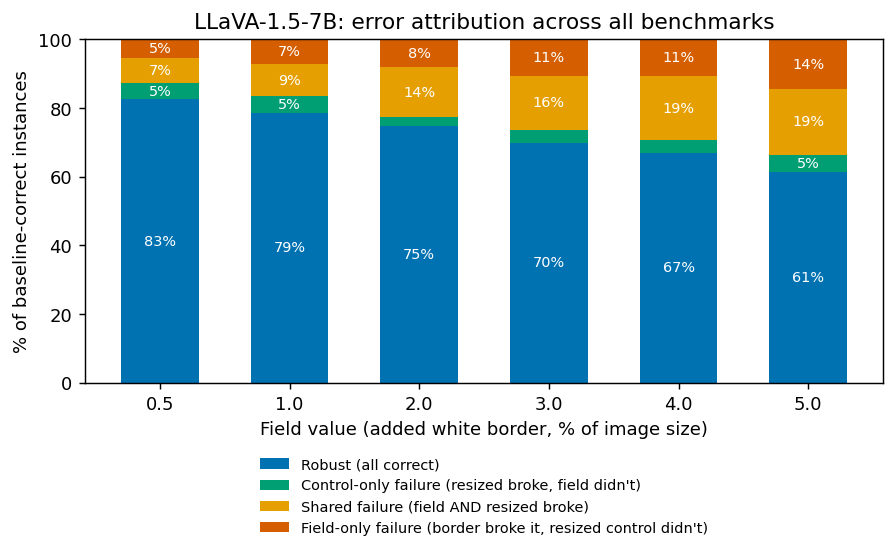

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(comp_pct.index))
bottom = np.zeros(len(comp_pct))
for cat in CATEGORY_ORDER:
    vals = comp_pct[cat].values
    ax.bar(x, vals, bottom=bottom, width=0.6, color=CATEGORY_COLORS[cat], label=CATEGORY_LABELS[cat])
    for xi, (v, b) in enumerate(zip(vals, bottom)):
        if v >= 4:
            ax.text(xi, b + v / 2, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white")
    bottom += vals

ax.set_xticks(x)
ax.set_xticklabels([str(v) for v in comp_pct.index])
ax.set_xlabel("Field value (added white border, % of image size)")
ax.set_ylabel("% of baseline-correct instances")
ax.set_title("LLaVA-1.5-7B: error attribution across all benchmarks")
ax.set_ylim(0, 100)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=1, fontsize=8, frameon=False)
fig.tight_layout()
plt.show()


The **field-only failure** share (the slice attributable specifically to the
border, since the same-resolution borderless control still succeeds) grows
from ~5% at field=0.5 to ~14% at field=5 - roughly comparable in size to
"shared failure" (pure resolution loss), meaning the border itself is doing
about as much damage as the accompanying downscale by the largest setting.


## Which benchmarks are most vulnerable to the border specifically?

Ranked by `field_only_failure` rate (among baseline-correct instances) at
the largest field value, i.e. which benchmarks break because of the border
even when an equally-downscaled, borderless image would still be answered
correctly.


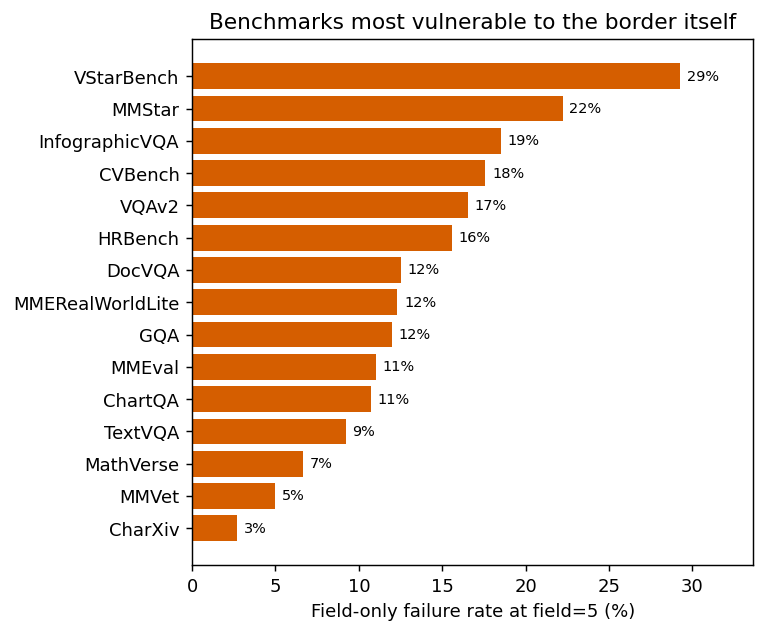

In [13]:
MAX_FIELD = at_risk["field_value"].max()
rank = (
    at_risk[at_risk["field_value"] == MAX_FIELD]
    .groupby("benchmark")["category"]
    .apply(lambda s: (s == "field_only_failure").mean() * 100)
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(6, 5))
y = np.arange(len(rank))
ax.barh(y, rank.values, color="#D55E00")
ax.set_yticks(y)
ax.set_yticklabels(rank.index)
ax.invert_yaxis()
for yi, v in zip(y, rank.values):
    ax.text(v + 0.4, yi, f"{v:.0f}%", va="center", fontsize=8)
ax.set_xlabel(f"Field-only failure rate at field={MAX_FIELD:g} (%)")
ax.set_title("Benchmarks most vulnerable to the border itself")
ax.set_xlim(0, rank.values.max() * 1.15)
fig.tight_layout()
plt.show()


## Inspecting concrete field-only failures

For the most-affected benchmark above, look at actual instances where the
bordered image broke LLaVA while the same-resolution borderless control still
got it right - these are the clearest evidence of a border/framing artifact
rather than a resolution artifact.


In [14]:
top_benchmark = rank.index[0]

flagged_keys = wide[
    (wide["benchmark"] == top_benchmark)
    & (wide["field_value"] == MAX_FIELD)
    & (wide["category"] == "field_only_failure")
]["key"]

detail = df[
    (df["benchmark"] == top_benchmark)
    & (df["field_value"] == MAX_FIELD)
    & (df["key"].isin(flagged_keys))
    & (df["variant"].isin(["field", "resized"]))
]

inspect = detail.pivot_table(
    index=["key", "question", "ground_truth"],
    columns="variant",
    values="generated_answer",
    aggfunc="first",
).reset_index().rename(columns={"field": "field_generated", "resized": "resized_generated"})

print(f"{top_benchmark}: {len(inspect)} field-only failures at field={MAX_FIELD:g}")
inspect[["question", "ground_truth", "field_generated", "resized_generated"]].head(10)


VStarBench: 24 field-only failures at field=5


variant                                                                                                                 question  ... resized_generated
0        What is the color of the mailbox?\n(A) red\n(B) white\n(C) black\n(D) yellow\nAnswer with the option's letter from t...  ...                 C
1        Is the color of the plastic bucket black or green?\n(A) green\n(B) black\nAnswer with the option's letter from the g...  ...                 A
2        What is the color of the cart?\n(A) green\n(B) white\n(C) black\n(D) silver\nAnswer with the option's letter from th...  ...                 A
3        What is the color of the telephone?\n(A) green\n(B) white\n(C) orange\n(D) blue\nAnswer with the option's letter fro...  ...                 C
4        What is the color of the woman's bikini?\n(A) white\n(B) red\n(C) black\n(D) yellow\nAnswer with the option's letter...  ...                 C
5        What is the color of the man's cap?\n(A) white\n(B) green\n(C) black\n(D) red\n

## Optional: view the images behind a flagged instance

Requires live access to the benchmark's HF dataset to rebuild the exact
field / resized images (`src.utils.build_field_images`) - skips gracefully if
that's not reachable (e.g. no network / offline environment).


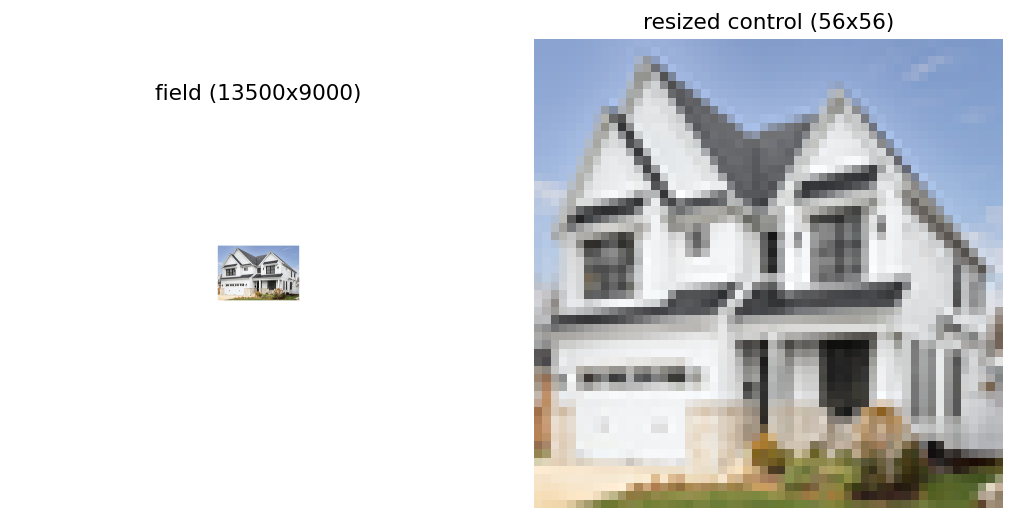

In [15]:
try:
    from transformers import AutoProcessor

    # src.benchmarks (not benchmarks_original) is what main_field.py actually
    # ran: its sample_indices_or_all() reproduces the same seed=42, size=200
    # random subset for any truthy `field`, regardless of the field percent,
    # so this recovers the exact instance the experiment scored.
    from src.benchmarks import (
        MMVetDataset, MMEvalDataset, MathVerseDataset, MMStar, CharXiv,
        VQAv2Dataset, GQADataset, CVBenchDataset, TextVQADataset, ChartQADataset,
        DocVQADataset, InfographicVQADataset, VStarBenchDataset, HRBenchDataset,
        MMERealWorldLiteDataset,
    )
    from src.utils import build_field_images

    DATASET_CLASSES = {
        "MMVet": MMVetDataset, "MMEval": MMEvalDataset, "MathVerse": MathVerseDataset,
        "MMStar": MMStar, "CharXiv": CharXiv, "VQAv2": VQAv2Dataset, "GQA": GQADataset,
        "CVBench": CVBenchDataset, "TextVQA": TextVQADataset, "ChartQA": ChartQADataset,
        "DocVQA": DocVQADataset, "InfographicVQA": InfographicVQADataset,
        "VStarBench": VStarBenchDataset, "HRBench": HRBenchDataset,
        "MMERealWorldLite": MMERealWorldLiteDataset,
    }

    MODEL_NAME = "llava-hf/llava-1.5-7b-hf"
    target_id = inspect.iloc[0]["key"][0]
    dataset = DATASET_CLASSES[top_benchmark](field=MAX_FIELD)
    sample = next(s for s in dataset if s["id"] == target_id)

    processor = AutoProcessor.from_pretrained(MODEL_NAME)
    field_img, resized_img, bicubic_img, info = build_field_images(
        processor, MODEL_NAME, sample["image"], field=MAX_FIELD,
    )

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(field_img)
    axes[0].set_title(f"field ({field_img.size[0]}x{field_img.size[1]})")
    axes[1].imshow(resized_img)
    axes[1].set_title(f"resized control ({resized_img.size[0]}x{resized_img.size[1]})")
    for a in axes:
        a.axis("off")
    fig.tight_layout()
    plt.show()
except Exception as e:
    print(f"Skipping image rebuild (needs live dataset/model access): {e!r}")


## CKA: representational divergence for instances that flip correct -> wrong under all three variants

A stricter subset than `shared_failure` above: instances LLaVA got right at
baseline (field=0) and got wrong under **all three** of field, resized *and*
bicubic at the largest field value - i.e. no borderless or blur-only control
saves it either, so whatever broke it isn't attributable to any one
transformation in isolation. For exactly these instances, we run the real
model and measure linear CKA (`src/cka.py`, reusing the extraction code in
`main_cka.py`) between the baseline activations and each corrupted
condition's activations, layer by layer, in both the vision tower and the
language model. This shows *where in the network* (and by how much) the
representation of a "hard" example diverges once the input is corrupted -
as opposed to the field/resized/bicubic split explored earlier
(main_cka.py), which used generic ChartQA samples rather than instances
tied to an actual model failure.


In [16]:
all_three_wrong = wide[
    (wide["field_value"] == MAX_FIELD)
    & (wide["baseline_score"] == 1.0)
    & (wide["field"] == 0.0)
    & (wide["resized"] == 0.0)
    & (wide["bicubic"] == 0.0)
]
print(f"{len(all_three_wrong)} instances correct at baseline, wrong under field AND resized AND bicubic at field={MAX_FIELD:g}")
all_three_wrong.groupby("benchmark").size().sort_values(ascending=False)


191 instances correct at baseline, wrong under field AND resized AND bicubic at field=5


benchmark
TextVQA             46
DocVQA              17
VQAv2               14
VStarBench          13
CVBench             12
MMERealWorldLite    11
GQA                 10
MMEval              10
HRBench              9
CharXiv              9
ChartQA              9
MMVet                9
MMStar               9
InfographicVQA       7
MathVerse            6
dtype: int64

### Extract activations and compute per-benchmark CKA

For each benchmark, the flagged instances' original images are refetched
from the benchmark's dataset (matched by `id`, the raw dataset field - the
`question` stored in the result files has an appended answer-format
instruction, so it no longer matches the dataset's raw question text) and
the field/resized/bicubic variants are rebuilt with the exact
`build_field_images` function the experiment used. Each condition is run
through LLaVA once with `output_hidden_states=True`; hidden states are
mean-pooled per layer (patch tokens for the vision tower, attention-mask-
weighted mean over the sequence for the language model - see
`main_cka.extract_pooled_batch`) to get one vector per instance per layer,
and linear CKA is computed between baseline and each corrupted condition.
This needs a live GPU + model weights + dataset access; skips a benchmark
(rather than the whole section) if anything about it isn't reachable.


In [17]:
from scripts.main_cka import load_model_and_processor, vision_input_short_edge, collect_activations
from src.cka import linear_cka

CKA_MODEL_NAME = "llava-hf/llava-1.5-7b-hf"
CKA_DEVICE = "cuda:0"
CKA_BATCH_SIZE = 8
CKA_PAIRS = [("baseline", "field"), ("baseline", "resized"), ("baseline", "bicubic")]
CKA_OUT_DIR = project_root / "results_cka"
CKA_OUT_DIR.mkdir(exist_ok=True)

cka_rows = []
try:
    cka_model, cka_processor = load_model_and_processor(CKA_MODEL_NAME, None, CKA_DEVICE)

    for benchmark, group in all_three_wrong.groupby("benchmark"):
        target_ids = set(group["key"].apply(lambda k: k[0]))
        try:
            dataset = DATASET_CLASSES[benchmark](field=MAX_FIELD)
            matched = [s for s in dataset if s["id"] in target_ids]
        except Exception as e:
            print(f"{benchmark}: SKIPPED, dataset unavailable ({e!r})")
            continue
        if len(matched) < 4:
            print(f"{benchmark}: SKIPPED, only {len(matched)} matched samples (need >= 4)")
            continue

        baseline_images, field_images, resized_images, bicubic_images, questions = [], [], [], [], []
        for sample in matched:
            image = sample["image"].convert("RGB")
            field_img, resized_img, bicubic_img, _ = build_field_images(
                cka_processor, CKA_MODEL_NAME, image, field=MAX_FIELD,
            )
            baseline_images.append(image)
            field_images.append(field_img)
            resized_images.append(resized_img)
            bicubic_images.append(bicubic_img)
            questions.append(sample["question"])

        conditions = {
            "baseline": baseline_images, "field": field_images,
            "resized": resized_images, "bicubic": bicubic_images,
        }
        vision_acts, lm_acts = {}, {}
        for name, imgs in conditions.items():
            v, l = collect_activations(cka_model, cka_processor, imgs, questions, CKA_DEVICE, CKA_BATCH_SIZE)
            vision_acts[name] = v
            lm_acts[name] = l

        for component, acts in [("vision_tower", vision_acts), ("language_model", lm_acts)]:
            for layer in range(len(acts["baseline"])):
                for cond_a, cond_b in CKA_PAIRS:
                    cka = linear_cka(acts[cond_a][layer], acts[cond_b][layer])
                    cka_rows.append({
                        "benchmark": benchmark, "component": component,
                        "pair": f"{cond_a}_vs_{cond_b}", "layer": layer,
                        "cka": cka, "n": len(matched),
                    })
        print(f"{benchmark}: n={len(matched)} - CKA computed")
except Exception as e:
    print(f"Skipping CKA section entirely (needs live GPU/model/dataset access): {e!r}")

cka_df = pd.DataFrame(cka_rows)
if len(cka_df):
    cka_df.to_csv(CKA_OUT_DIR / "llava_field_flip_cka_per_benchmark.csv", index=False)
print(f"{len(cka_df)} (benchmark, component, pair, layer) CKA rows across {cka_df['benchmark'].nunique() if len(cka_df) else 0} benchmarks")


CVBench: n=12 - CKA computed
CharXiv: n=9 - CKA computed
ChartQA: n=9 - CKA computed
DocVQA: n=17 - CKA computed
GQA: n=10 - CKA computed
HRBench: n=9 - CKA computed
InfographicVQA: n=7 - CKA computed
MMERealWorldLite: n=11 - CKA computed
MMEval: n=10 - CKA computed
MMStar: n=9 - CKA computed
MMVet: n=9 - CKA computed
MathVerse: n=6 - CKA computed
TextVQA: n=46 - CKA computed
VQAv2: n=14 - CKA computed
VStarBench: n=13 - CKA computed
2610 (benchmark, component, pair, layer) CKA rows across 15 benchmarks


### Mean, deviation band, and min/max across benchmarks, per layer

Each benchmark contributes one CKA value per layer per pair (computed from
that benchmark's own flagged instances). Aggregating across benchmarks at
each layer gives a distribution rather than a single curve: the solid line
is the cross-benchmark mean, the dark band is +-1 std, and the light outer
band spans the full min-max range - so a layer where all benchmarks agree
(tight bands) reads very differently from one where they diverge widely
(wide bands) even if the means match.


In [18]:
cka_agg = (
    cka_df.groupby(["component", "pair", "layer"])["cka"]
    .agg(mean="mean", std="std", min="min", max="max", n_benchmarks="count")
    .reset_index()
)
cka_agg.to_csv(CKA_OUT_DIR / "llava_field_flip_cka_aggregate.csv", index=False)
cka_agg.head()


        component                 pair  layer  ...       min       max  n_benchmarks
0  language_model  baseline_vs_bicubic      0  ...  0.324822  0.953450            15
1  language_model  baseline_vs_bicubic      1  ...  0.325581  0.953501            15
2  language_model  baseline_vs_bicubic      2  ...  0.328290  0.955428            15
3  language_model  baseline_vs_bicubic      3  ...  0.330498  0.956528            15
4  language_model  baseline_vs_bicubic      4  ...  0.332480  0.957103            15

[5 rows x 8 columns]

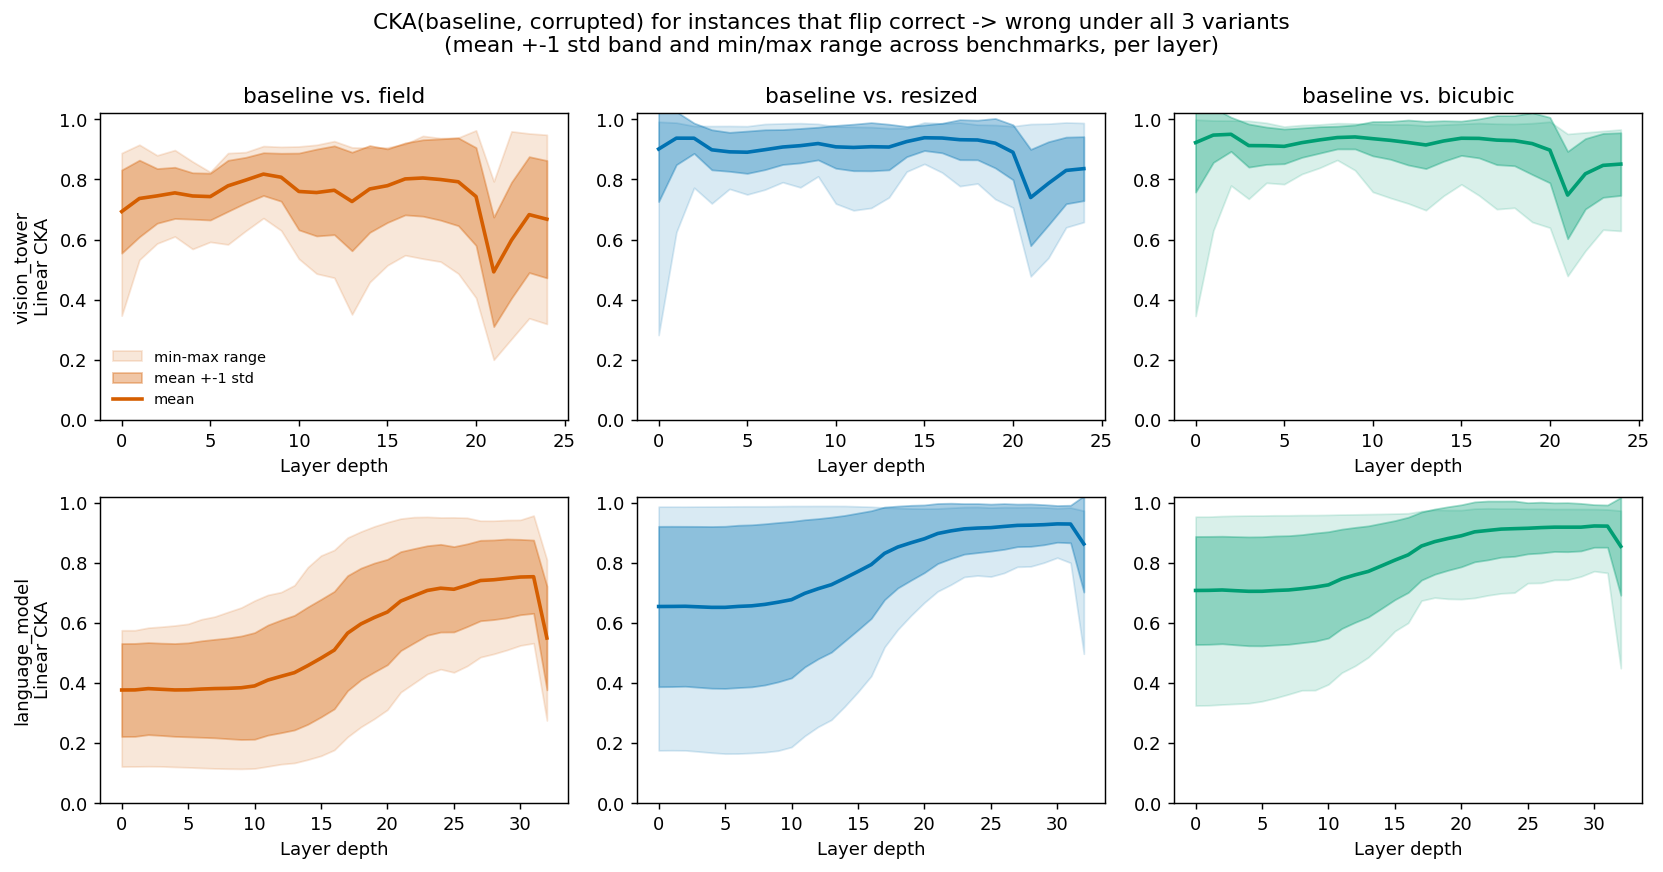

In [19]:
CKA_COMPONENTS = ["vision_tower", "language_model"]
CKA_PAIR_ORDER = ["baseline_vs_field", "baseline_vs_resized", "baseline_vs_bicubic"]
CKA_PAIR_COLORS = {
    "baseline_vs_field": "#D55E00",
    "baseline_vs_resized": "#0072B2",
    "baseline_vs_bicubic": "#009E73",
}

present_components = [c for c in CKA_COMPONENTS if c in set(cka_agg["component"])]
fig, axes = plt.subplots(
    len(present_components), len(CKA_PAIR_ORDER),
    figsize=(4.3 * len(CKA_PAIR_ORDER), 3.4 * len(present_components)),
    squeeze=False,
)

for row, component in enumerate(present_components):
    for col, pair in enumerate(CKA_PAIR_ORDER):
        ax = axes[row][col]
        sub = cka_agg[(cka_agg["component"] == component) & (cka_agg["pair"] == pair)].sort_values("layer")
        color = CKA_PAIR_COLORS[pair]
        if sub.empty:
            ax.axis("off")
            continue
        ax.fill_between(sub["layer"], sub["min"], sub["max"], color=color, alpha=0.15, label="min-max range")
        ax.fill_between(sub["layer"], sub["mean"] - sub["std"], sub["mean"] + sub["std"], color=color, alpha=0.35, label="mean +-1 std")
        ax.plot(sub["layer"], sub["mean"], color=color, linewidth=2, label="mean")
        ax.set_ylim(0, 1.02)
        ax.set_xlabel("Layer depth")
        if col == 0:
            ax.set_ylabel(f"{component}\nLinear CKA")
        if row == 0:
            ax.set_title(pair.replace("_vs_", " vs. "))

axes[0][0].legend(fontsize=8, loc="lower left", frameon=False)
fig.suptitle("CKA(baseline, corrupted) for instances that flip correct -> wrong under all 3 variants\n(mean +-1 std band and min/max range across benchmarks, per layer)")
fig.tight_layout()
fig.savefig(CKA_OUT_DIR / "llava_field_flip_cka.png", dpi=140, bbox_inches="tight")
plt.show()


## Flip-flop instances: correct -> wrong -> correct again

A different instance class from the two sections above: restricted to the
**field** variant's sweep (0.5, 1, 2, 3, 4, 5) - the border, since it's the
transformation the rest of this notebook is centered on and it has the
richest pool of these instances - instances where LLaVA was correct at
baseline, wrong at *some* intermediate field value, and correct again at the
largest field value (5). For each such instance we pick two conditions to
compare against baseline:

- **wrong**: the field image at the *last* intermediate value where the
  answer was still wrong (the point right before recovery),
- **recovered**: the field image at field=5, where the answer is correct
  again despite being the *most* distorted image in the whole sweep.

This ordering matters: `recovered` is always at least as heavily bordered as
`wrong` (5 >= any intermediate value), so if CKA(baseline, recovered) still
comes out *higher* (more similar) than CKA(baseline, wrong) despite being the
more distorted input, that's evidence CKA is tracking answer-correctness
itself, not merely how much the input changed - the opposite of what a naive
"more distortion = more divergence" story would predict.


In [20]:
flip_df = df[df["variant"] == "field"]
FF_INTERMEDIATE = [float(v) for v in NEW_VALUES if float(v) != MAX_FIELD]

ff_pivot = flip_df.pivot_table(
    index=["benchmark", "key", "baseline_score"], columns="field_value", values="score", aggfunc="first"
).reset_index()
ff_pivot.columns.name = None

ff_has_wrong = (ff_pivot[FF_INTERMEDIATE] == 0.0).any(axis=1)
flipflop = ff_pivot[
    (ff_pivot["baseline_score"] == 1.0) & (ff_pivot[MAX_FIELD] == 1.0) & ff_has_wrong
].copy()
flipflop["wrong_value"] = flipflop.apply(
    lambda row: max(v for v in FF_INTERMEDIATE if row[v] == 0.0), axis=1
)
flipflop = flipflop.groupby("benchmark").filter(lambda g: len(g) >= 4)

print(f"{len(flipflop)} correct->wrong->correct-again instances across {flipflop['benchmark'].nunique()} benchmarks (benchmarks with <4 such instances excluded)")
flipflop.groupby("benchmark").size().sort_values(ascending=False)


90 correct->wrong->correct-again instances across 10 benchmarks (benchmarks with <4 such instances excluded)


benchmark
VStarBench          17
HRBench             11
MMEval              11
MMERealWorldLite    11
GQA                  9
VQAv2                8
CVBench              7
MMStar               6
MathVerse            6
TextVQA              4
dtype: int64

### Extract activations and compute per-benchmark CKA


In [21]:
FF_CKA_PAIRS = [("baseline", "wrong"), ("baseline", "recovered")]
ff_rows = []
try:
    for benchmark, group in flipflop.groupby("benchmark"):
        # Join on `id` only (see the per-instance join note above); take the
        # first wrong_value seen per id if a benchmark has any id collisions.
        id_to_wrong_value = {}
        for k, wv in zip(group["key"], group["wrong_value"]):
            id_to_wrong_value.setdefault(k[0], wv)
        target_ids = set(id_to_wrong_value)

        try:
            dataset = DATASET_CLASSES[benchmark](field=MAX_FIELD)
        except Exception as e:
            print(f"{benchmark}: SKIPPED, dataset unavailable ({e!r})")
            continue
        seen_ids, matched = set(), []
        for s in dataset:
            if s["id"] in target_ids and s["id"] not in seen_ids:
                seen_ids.add(s["id"])
                matched.append((s, id_to_wrong_value[s["id"]]))
        if len(matched) < 4:
            print(f"{benchmark}: SKIPPED, only {len(matched)} matched samples (need >= 4)")
            continue

        baseline_images, wrong_images, recovered_images, questions = [], [], [], []
        for sample, wrong_value in matched:
            image = sample["image"].convert("RGB")
            wrong_img, _, _, _ = build_field_images(cka_processor, CKA_MODEL_NAME, image, field=wrong_value)
            recovered_img, _, _, _ = build_field_images(cka_processor, CKA_MODEL_NAME, image, field=MAX_FIELD)
            baseline_images.append(image)
            wrong_images.append(wrong_img)
            recovered_images.append(recovered_img)
            questions.append(sample["question"])

        conditions = {"baseline": baseline_images, "wrong": wrong_images, "recovered": recovered_images}
        vision_acts, lm_acts = {}, {}
        for name, imgs in conditions.items():
            v, l = collect_activations(cka_model, cka_processor, imgs, questions, CKA_DEVICE, CKA_BATCH_SIZE)
            vision_acts[name] = v
            lm_acts[name] = l

        for component, acts in [("vision_tower", vision_acts), ("language_model", lm_acts)]:
            for layer in range(len(acts["baseline"])):
                for cond_a, cond_b in FF_CKA_PAIRS:
                    cka = linear_cka(acts[cond_a][layer], acts[cond_b][layer])
                    ff_rows.append({
                        "benchmark": benchmark, "component": component,
                        "pair": f"{cond_a}_vs_{cond_b}", "layer": layer,
                        "cka": cka, "n": len(matched),
                    })
        print(f"{benchmark}: n={len(matched)} - CKA computed")
except Exception as e:
    print(f"Skipping flip-flop CKA section entirely (needs live GPU/model/dataset access): {e!r}")

ff_cka_df = pd.DataFrame(ff_rows)
if len(ff_cka_df):
    ff_cka_df.to_csv(CKA_OUT_DIR / "llava_flipflop_cka_per_benchmark.csv", index=False)
print(f"{len(ff_cka_df)} (benchmark, component, pair, layer) CKA rows across {ff_cka_df['benchmark'].nunique() if len(ff_cka_df) else 0} benchmarks")


CVBench: n=7 - CKA computed
GQA: n=9 - CKA computed
HRBench: n=11 - CKA computed
MMERealWorldLite: n=10 - CKA computed
MMEval: n=11 - CKA computed
MMStar: n=6 - CKA computed
MathVerse: n=6 - CKA computed
TextVQA: n=4 - CKA computed
VQAv2: n=8 - CKA computed
VStarBench: n=17 - CKA computed
1160 (benchmark, component, pair, layer) CKA rows across 10 benchmarks


### Comparing CKA(baseline, wrong) vs. CKA(baseline, recovered)

Both pairs overlaid on the same axes (one per component) - the direct
comparison the earlier per-benchmark section couldn't show, since here there
are only two conditions rather than three.


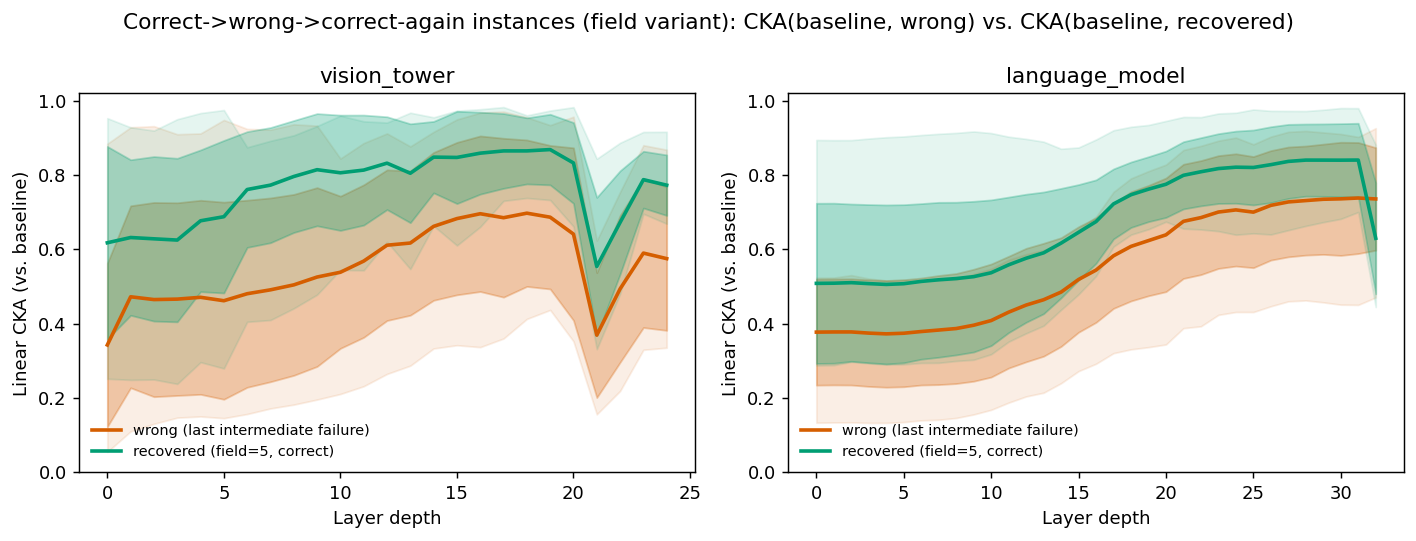

In [22]:
ff_agg = (
    ff_cka_df.groupby(["component", "pair", "layer"])["cka"]
    .agg(mean="mean", std="std", min="min", max="max", n_benchmarks="count")
    .reset_index()
)
ff_agg.to_csv(CKA_OUT_DIR / "llava_flipflop_cka_aggregate.csv", index=False)

FF_PAIR_COLORS = {"baseline_vs_wrong": "#D55E00", "baseline_vs_recovered": "#009E73"}
FF_PAIR_LABELS = {"baseline_vs_wrong": "wrong (last intermediate failure)", "baseline_vs_recovered": "recovered (field=5, correct)"}

present_components = [c for c in CKA_COMPONENTS if c in set(ff_agg["component"])]
fig, axes = plt.subplots(1, len(present_components), figsize=(5.5 * len(present_components), 4.2), squeeze=False)
axes = axes[0]

for ax, component in zip(axes, present_components):
    for pair in ["baseline_vs_wrong", "baseline_vs_recovered"]:
        sub = ff_agg[(ff_agg["component"] == component) & (ff_agg["pair"] == pair)].sort_values("layer")
        if sub.empty:
            continue
        color = FF_PAIR_COLORS[pair]
        ax.fill_between(sub["layer"], sub["min"], sub["max"], color=color, alpha=0.10)
        ax.fill_between(sub["layer"], sub["mean"] - sub["std"], sub["mean"] + sub["std"], color=color, alpha=0.28)
        ax.plot(sub["layer"], sub["mean"], color=color, linewidth=2, label=FF_PAIR_LABELS[pair])
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Layer depth")
    ax.set_ylabel("Linear CKA (vs. baseline)")
    ax.set_title(component)
    ax.legend(fontsize=8, loc="lower left", frameon=False)

fig.suptitle("Correct->wrong->correct-again instances (field variant): CKA(baseline, wrong) vs. CKA(baseline, recovered)")
fig.tight_layout()
fig.savefig(CKA_OUT_DIR / "llava_flipflop_cka.png", dpi=140, bbox_inches="tight")
plt.show()


## Attention maps: where does LLaVA actually look?

Everything above is behavioral (does the answer flip) or representational
(does the hidden state diverge) - this section looks one level lower, at the
decoder's actual attention over image-patch tokens, to see *where* LLaVA is
reading from when an instance falls into the **field_only_failure** category
from the accounting above: correct at baseline, correct on the `resized`
control (same effective content resolution as `field`, just no border) -
so there's no information loss to blame - yet wrong on `field`. That
combination isolates the border/framing itself as the cause, not resolution.

This needs `attn_implementation="eager"`: sdpa/flash-attention (used
everywhere else in this repo, including `cka_model` above) never materialize
attention weights at all, so a separate model instance is loaded just for
this section (`src/attention_viz.py`). For each variant, attention is
averaged over every generated token, the back half of decoder layers (early
layers mix generic low-level features with near-uniform attention; the
content-driven localization this is after only shows up later), and all
heads, restricted to the image-patch key positions - then reshaped to the
24x24 CLIP-ViT patch grid and overlaid on the exact 336x336 image the vision
tower encoded (reconstructed by inverting the processor's own
normalization, so the overlay is pixel-aligned with the grid by
construction, independent of the processor's internal resize/crop details).

One real caveat visible in the maps below: LLaVA's CLIP-ViT backbone has no
register tokens, so a handful of fixed high-norm "sink" patches absorb
disproportionate attention regardless of content (a documented
register-free-ViT artifact, not a bug here) - the color scale is clipped to
the 99th percentile across all variants in a figure so this doesn't wash out
the content-driven signal underneath it.

**Sample: DocVQA #104** ("What is written inside the diagram?", ground
truth `PROTECT`) at **field=0.5** - picked specifically for a clean
`field_only_failure` at a *mild* setting (found by scanning the already-scored
OCR benchmarks - DocVQA/TextVQA/ChartQA/InfographicVQA - for instances where
baseline and `resized` both score correct but `field` doesn't). The actual
scored run got: baseline `"Protect"` (correct), `field=0.5` `"Project"`
(wrong - a literal one-letter OCR misread), `resized=0.5` `"Protect"`
(correct again). Field values above 1.0 stop giving this clean split for this
instance (either the answer stops flipping, or the image degrades enough that
every variant fails - real information loss dominates instead), which is
itself informative: the border-only failure mode is a narrow, mild-severity
effect that gets swamped by resolution loss at higher field values, not one
that scales smoothly with border size. The same code is also a standalone CLI
(`python main_attention.py --benchmark docvqa --sample_index 104
--field_values 0.5 --downsize_scales`) for any of the OCR-flavored benchmarks
and any sample index.


In [3]:
import logging

logging.getLogger("httpx").setLevel(logging.WARNING)
logging.getLogger("huggingface_hub").setLevel(logging.WARNING)
from huggingface_hub.utils import disable_progress_bars
disable_progress_bars()
from transformers.utils.logging import set_verbosity_error as _set_transformers_verbosity_error
_set_transformers_verbosity_error()

from src.attention_viz import load_llava, compute_attention_map, plot_attention_grid
from scripts.main_attention import BENCHMARK_CLASSES, build_variants
from scripts.main_field import BENCHMARK_ANSWER_FORMAT_SUFFIXES
from src.parse_results import score_short_answer

ATTN_MODEL_NAME = "llava-hf/llava-1.5-7b-hf"
ATTN_DEVICE = "cuda:0"
ATTN_BENCHMARK = "docvqa"
ATTN_SAMPLE_INDEX = 104  # DocVQA id 55119: baseline correct, field=0.5 wrong, resized=0.5 correct again
ATTN_FIELD_VALUES = [0.5]
ATTN_DOWNSIZE_SCALES = []
ATTN_OUT_DIR = project_root / "results_attention"
ATTN_OUT_DIR.mkdir(exist_ok=True)

try:
    attn_model, attn_processor = load_llava(ATTN_MODEL_NAME, ATTN_DEVICE)

    # sample_size fixed at the dataset class's own default (200) - the seeded random subset this
    # instance's index was found in - see main_attention.py's comment on why a different
    # sample_size would silently point at the wrong image.
    attn_dataset = BENCHMARK_CLASSES[ATTN_BENCHMARK](field=1)
    attn_sample = attn_dataset[ATTN_SAMPLE_INDEX]
    # Must match main_field.py's actual prompt exactly (raw question + benchmark-specific
    # answer-format suffix), or the model answers more verbosely and this instance's specific
    # correct/wrong split may not reproduce.
    attn_question = attn_sample["question"] + BENCHMARK_ANSWER_FORMAT_SUFFIXES.get(ATTN_BENCHMARK, "")
    print(f"{ATTN_BENCHMARK} #{ATTN_SAMPLE_INDEX}: {attn_question!r} "
          f"(ground truth: {attn_sample['answer']!r})")

    attn_variants = build_variants(attn_processor, ATTN_MODEL_NAME, attn_sample["image"],
                                    ATTN_FIELD_VALUES, ATTN_DOWNSIZE_SCALES)

    attn_rows = []
    for label, variant_image in attn_variants.items():
        result = compute_attention_map(attn_model, attn_processor, variant_image,
                                        attn_question, ATTN_DEVICE, max_new_tokens=16)
        correct = score_short_answer(result["generated_answer"], attn_sample["answer"]) == 1.0
        print(f"  {label:16s} ({variant_image.size[0]}x{variant_image.size[1]}) "
              f"-> {result['generated_answer']!r} ({'correct' if correct else 'wrong'})")
        attn_rows.append({
            "label": f"{label} ({variant_image.size[0]}x{variant_image.size[1]})",
            "model_view": result["model_view"],
            "attn_grid": result["attn_grid"],
            "generated_answer": result["generated_answer"],
            "correct": correct,
        })
except Exception as e:
    attn_rows = []
    print(f"Skipping attention-map section (needs live GPU/model/dataset access): {e!r}")


/home/colligo/Waldo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-07-26 09:41:57,929 - INFO - Loading llava-hf/llava-1.5-7b-hf onto cuda:0 (attn_implementation=eager)


2026-07-26 09:42:09,767 - INFO - Loaded 200 samples from DocVQA dataset


docvqa #104: 'What is written inside the diagram?\nAnswer the question using a single word or phrase.' (ground truth: 'PROTECT')


  original         (1643x2153) -> 'Protect' (correct)


  field=0.5        (2464x3229) -> 'Project' (wrong)


  resized=0.5      (224x224) -> 'Protect' (correct)


  bicubic=0.5      (1643x2153) -> 'Protect' (correct)


2026-07-26 09:42:13,097 - INFO - Saved attention map figure to /home/colligo/Waldo/results_attention/docvqa_llava-hf_llava-1.5-7b-hf_sample104_attention.png


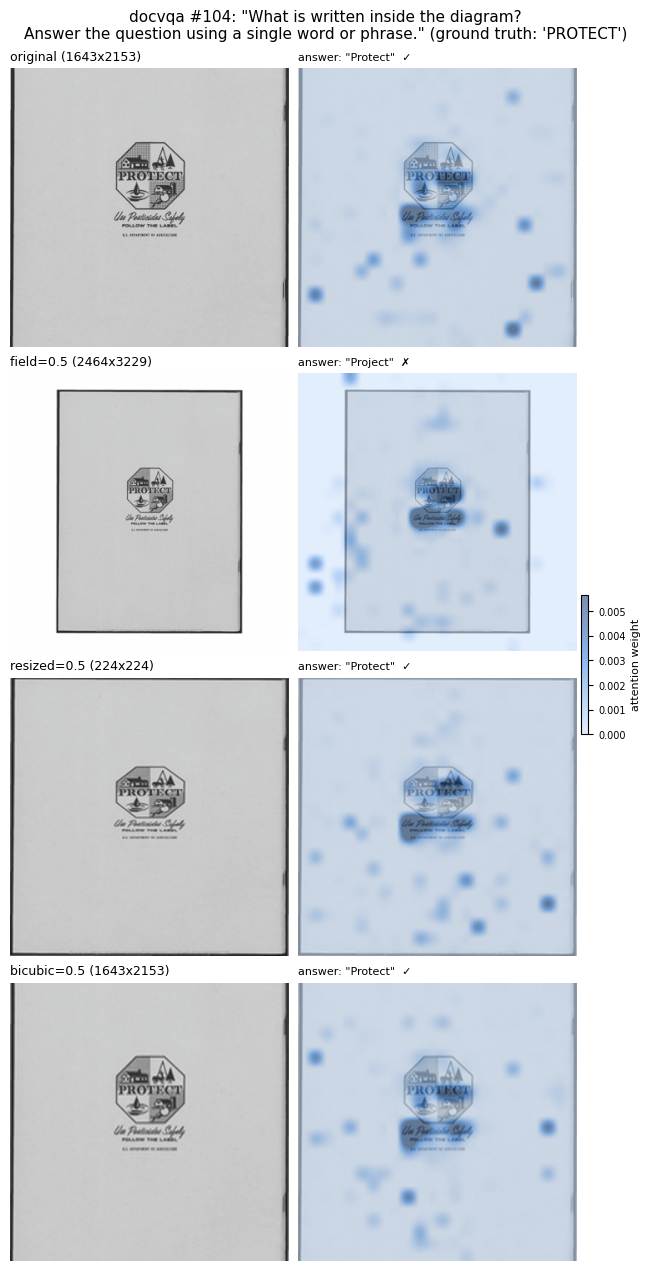

In [4]:
if attn_rows:
    attn_out_file = ATTN_OUT_DIR / f"{ATTN_BENCHMARK}_{ATTN_MODEL_NAME.replace('/', '_')}_sample{ATTN_SAMPLE_INDEX}_attention.png"
    fig = plot_attention_grid(
        attn_rows, output_file=attn_out_file,
        suptitle=f"{ATTN_BENCHMARK} #{ATTN_SAMPLE_INDEX}: \"{attn_question}\" "
                 f"(ground truth: {attn_sample['answer']!r})",
        close=False,
    )
    plt.show()


On the original image, attention concentrates tightly on the "PROTECT" text
inside the logo and the model reads it correctly. Adding only a mild (50%)
white border - which doesn't visibly blur or shrink the readable text by much
- is enough to pull attention away from the word itself (onto the line below
it) and the model misreads "Protect" as "Project". Removing the border again
(`resized`/`bicubic`, at the exact same effective content resolution `field`
had) snaps attention back onto the text and the answer is correct again. Since
`resized` and `bicubic` prove the content itself lost no information at this
setting, the flip is attributable specifically to the border/framing
perturbing attention - a much sharper, single-instance version of the
aggregate field-only-failure story earlier in this notebook, now visible
directly in the attention weights rather than inferred from accuracy alone.


### Patch boundaries: what grid is the model actually applying?

LLaVA's CLIPImageProcessor resizes every input's shortest edge to 336px
(aspect-preserving) then center-crops to 336x336 before patchifying at
`patch_size=14` - a fixed 24x24 grid. That means the patch *boundaries*, in
the 336x336 space the model actually operates in, are identical for every
variant (`0, 14, 28, ..., 336` on both axes) - the grid itself never changes.
What changes per variant is where that fixed grid lands back in the
*original* image, and how many original pixels a single 14x14 patch spans -
i.e. how much each variant's own preprocessing has already compressed its
content before the model patchifies it at all.


Patch grid in the model's own 336x336 input space is IDENTICAL for every variant:
  boundaries at [0, 14, 28, 42, 56, 70, 84, 98, 112, 126, 140, 154, 168, 182, 196, 210, 224, 238, 252, 266, 280, 294, 308, 322, 336] px  (24x24 patches, 14x14 px each)

Where that fixed grid maps back into each variant's own original image:
  original         original=1643x2153  resize_scale=0.2045  resized_to=336x440  crop_box_in_resized_px=(0, 52, 336, 388)  -> 1 patch = 68.5px of the original
  field=0.5        original=2464x3229  resize_scale=0.1364  resized_to=336x440  crop_box_in_resized_px=(0, 52, 336, 388)  -> 1 patch = 102.7px of the original
  resized=0.5      original=224x224  resize_scale=1.5000  resized_to=336x336  crop_box_in_resized_px=(0, 0, 336, 336)  -> 1 patch = 9.3px of the original
  bicubic=0.5      original=1643x2153  resize_scale=0.2045  resized_to=336x440  crop_box_in_resized_px=(0, 52, 336, 388)  -> 1 patch = 68.5px of the original


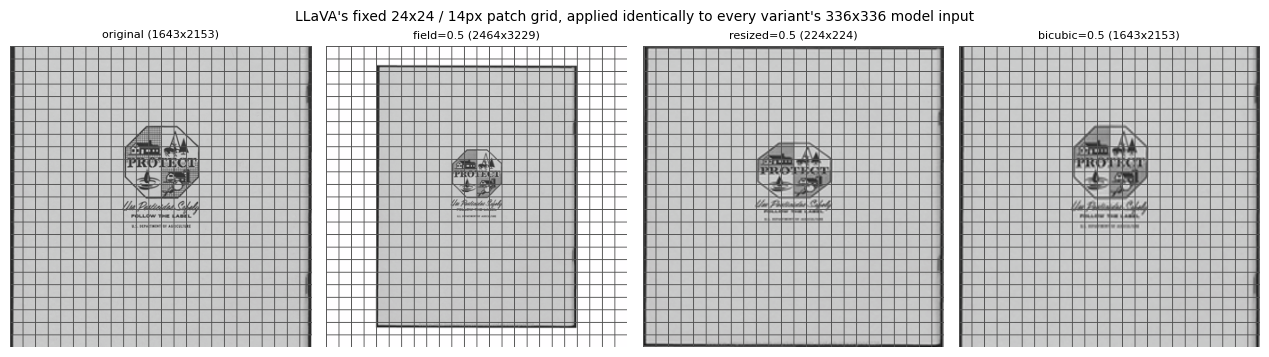

In [5]:
from src.attention_viz import patch_grid_info, draw_patch_grid

if attn_rows:
    fixed_boundaries = patch_grid_info(attn_rows[0]["model_view"].size)["boundaries_model_px"]
    print(f"Patch grid in the model's own 336x336 input space is IDENTICAL for every variant:")
    print(f"  boundaries at {fixed_boundaries} px  (24x24 patches, 14x14 px each)\n")
    print("Where that fixed grid maps back into each variant's own original image:")

    for (label, variant_image), row in zip(attn_variants.items(), attn_rows):
        info = patch_grid_info(variant_image.size)
        print(f"  {label:16s} original={info['original_size'][0]}x{info['original_size'][1]}  "
              f"resize_scale={info['resize_scale']:.4f}  "
              f"resized_to={info['resized_size'][0]}x{info['resized_size'][1]}  "
              f"crop_box_in_resized_px={tuple(round(c) for c in info['crop_box_in_resized_px'])}  "
              f"-> 1 patch = {info['patch_size_in_original_px']:.1f}px of the original")

    fig, axes = plt.subplots(1, len(attn_rows), figsize=(3.2 * len(attn_rows), 3.6))
    for ax, row in zip(axes, attn_rows):
        ax.imshow(draw_patch_grid(row["model_view"]))
        ax.set_title(row["label"], fontsize=8)
        ax.axis("off")
    fig.suptitle("LLaVA's fixed 24x24 / 14px patch grid, applied identically to every variant's 336x336 model input",
                 fontsize=10)
    fig.tight_layout()
    patch_grid_file = ATTN_OUT_DIR / f"{ATTN_BENCHMARK}_sample{ATTN_SAMPLE_INDEX}_patch_grid.png"
    fig.savefig(patch_grid_file, dpi=160, bbox_inches="tight")
    plt.show()
